In [1]:
from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/TrustFact")
DATA_DIR = BASE / "data/raw/liar"
OUTPUT_DIR = BASE / "results/week4"

columns = [
    "id", "label", "statement", "subject", "speaker",
    "speaker_job", "state", "party",
    "barely_true_count", "false_count",
    "half_true_count", "mostly_true_count",
    "pants_on_fire_count", "context"
]

train_df = pd.read_csv(
    DATA_DIR / "train.tsv",
    sep="\t", header=None, names=columns
)

valid_df = pd.read_csv(
    DATA_DIR / "valid.tsv",
    sep="\t", header=None, names=columns
)

X_train = train_df["statement"].fillna("").astype(str)
y_train = train_df["label"]

X_valid = valid_df["statement"].fillna("").astype(str)
y_valid = valid_df["label"]

print("Training:", len(X_train))
print("Validation:", len(X_valid))

Mounted at /content/drive
Training: 10240
Validation: 1284


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from itertools import product
import joblib

experiments = []
best_model = None
best_f1 = -1

ngram_options = [(1, 1), (1, 2)]
feature_options = [10000, 20000, 30000]
c_options = [0.1, 1.0, 10.0]

for ngram, features, c in product(
    ngram_options, feature_options, c_options
):
    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=features,
            ngram_range=ngram,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            C=c,
            max_iter=2000,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)

    accuracy = accuracy_score(y_valid, predictions)
    macro_f1 = f1_score(
        y_valid, predictions, average="macro"
    )

    experiments.append({
        "ngram": str(ngram),
        "max_features": features,
        "C": c,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_model = model

results = pd.DataFrame(experiments).sort_values(
    "macro_f1", ascending=False
)

display(results.head(10))

results.to_csv(
    OUTPUT_DIR / "lr_hyperparameter_search.csv",
    index=False
)

joblib.dump(
    best_model,
    OUTPUT_DIR / "best_tuned_lr.joblib"
)

print("Best validation macro-F1:", round(best_f1, 4))
print("Optimization results saved.")

,ngram,max_features,C,accuracy,macro_f1
17,"(1, 2)",30000,10.0,0.267134,0.261930
14,"(1, 2)",20000,10.0,0.259346,0.252203
11,"(1, 2)",10000,10.0,0.245327,0.242484
5,"(1, 1)",20000,10.0,0.249221,0.242224
8,"(1, 1)",30000,10.0,0.249221,0.242224
2,"(1, 1)",10000,10.0,0.239097,0.233996
16,"(1, 2)",30000,1.0,0.254673,0.233805
13,"(1, 2)",20000,1.0,0.254673,0.232847
4,"(1, 1)",20000,1.0,0.250000,0.230351
7,"(1, 1)",30000,1.0,0.250000,0.230351


Best validation macro-F1: 0.2619
Optimization results saved.


In [3]:
baseline = pd.read_csv(
    OUTPUT_DIR / "baseline_model_comparison.csv"
)

optimized = pd.DataFrame([{
    "Model": "Optimized Logistic Regression",
    "Accuracy": results.iloc[0]["accuracy"],
    "Macro-F1": results.iloc[0]["macro_f1"]
}])

comparison = pd.concat(
    [baseline, optimized],
    ignore_index=True
)

comparison = comparison.sort_values(
    "Macro-F1", ascending=False
)

display(comparison)

comparison.to_csv(
    OUTPUT_DIR / "optimized_model_comparison.csv",
    index=False
)

,Model,Accuracy,Macro-F1
2,Optimized Logistic Regression,0.267134,0.261930
1,Linear SVM,0.262461,0.258223
0,Logistic Regression,0.253115,0.232384


,precision,recall,f1-score,support
pants-fire,0.344262,0.181034,0.237288,116.000000
false,0.260073,0.269962,0.264925,263.000000
barely-true,0.239024,0.206751,0.221719,237.000000
half-true,0.274576,0.326613,0.298343,248.000000
mostly-true,0.292969,0.298805,0.295858,251.000000
true,0.237113,0.272189,0.253444,169.000000
accuracy,0.267134,0.267134,0.267134,0.267134
macro avg,0.274670,0.259226,0.261930,1284.000000
weighted avg,0.270004,0.267134,0.265444,1284.000000


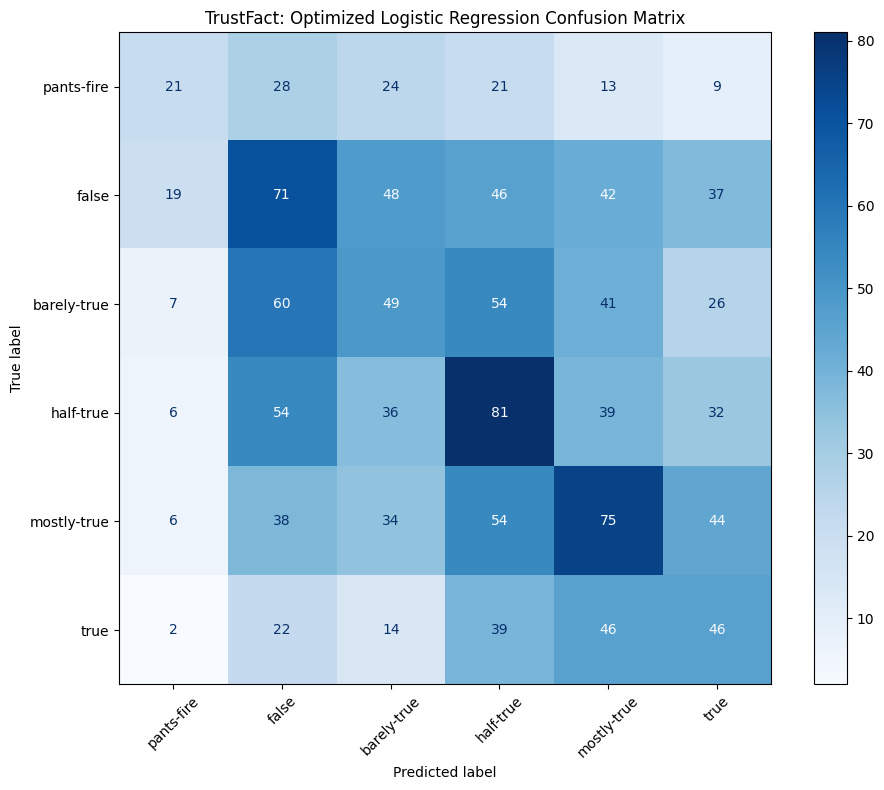

In [4]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

labels = [
    "pants-fire", "false", "barely-true",
    "half-true", "mostly-true", "true"
]

best_predictions = best_model.predict(X_valid)

# Classification report
report = classification_report(
    y_valid,
    best_predictions,
    labels=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
display(report_df)

report_df.to_csv(
    OUTPUT_DIR / "optimized_lr_classification_report.csv"
)

# Confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    best_predictions,
    labels=labels,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("TrustFact: Optimized Logistic Regression Confusion Matrix")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "optimized_lr_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
best_params = results.iloc[0]

print("Best hyperparameter configuration:")
print(best_params.to_string())

best_params.to_frame(name="value").to_csv(
    OUTPUT_DIR / "best_lr_hyperparameters.csv"
)

print("\nBest model saved at:")
print(OUTPUT_DIR / "best_tuned_lr.joblib")

Best hyperparameter configuration:
ngram             (1, 2)
max_features       30000
C                   10.0
accuracy        0.267134
macro_f1         0.26193

Best model saved at:
/content/drive/MyDrive/TrustFact/results/week4/best_tuned_lr.joblib
